In [1]:
"""
looknig at sobel filted edge detection to find cosmic rays
"""

'\nlooknig at sobel filted edge detection to find cosmic rays\n'

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import imageio as iio
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from astropy.io import fits
import scipy.ndimage as snm

In [2]:
from tqdm.auto import tqdm
import os
from pylab import cm
import matplotlib as mpl
import get_postage_stamps as gpsf
import pandas as pd

In [4]:
#import plot_time_series as pts
#import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name

In [5]:
"""
COSMIC RAYS
okay back to trying to find sharp edges
take the images try one with CR and one with regular transients, apply the sobel filter and see how sharp the edges are
ignore the perpendicular edges, only look at the other one
it will give us a 2d map, we will threshold it
and then also check the position

we will see what happens and if it doesn’t work go back to 1D
"""

'\nCOSMIC RAYS\nokay back to trying to find sharp edges\ntake the images try one with CR and one with regular transients, apply the sobel filter and see how sharp the edges are\nignore the perpendicular edges, only look at the other one\nit will give us a 2d map, we will threshold it\nand then also check the position\n\nwe will see what happens and if it doesn’t work go back to 1D\n'

In [6]:
# some matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [9]:
cr = "ztf_20221020148032_000686_zg_c16_x_0001.fits"

In [10]:
import review_findings_functions as ff

In [11]:
direcnames = [
    "20210622",
    "0820_real_this_time",
    "1014",
    "1017",
    "1019",
    "1020",
    "1026,",
    "20220808",
]
wid = 10

In [12]:
df_0820 = ff.getdf("0820_real_this_time")
df_1014 = ff.getdf("1014")

/lustre/lrspec/ZTF_data/science_extractions/0820_real_this_time/df_detections_0820_real_this_time


FileNotFoundError: [Errno 2] No such file or directory: '/lustre/lrspec/ZTF_data/science_extractions/0820_real_this_time/df_detections_0820_real_this_time'

In [10]:
df_0820 = pd.read_

,Unnamed: 0,filename,row_from_nn,col_from_nn,detection_size,cosmic_ray_flag,max brightness
0,0,ztf_20220820237546_000798_zr_c05_x_0004.,88.0,2027.0,2,0.000649,0.059300
1,1,ztf_20220820237546_000798_zr_c05_x_0000.,13.0,2582.0,74,0.993035,0.933589
2,2,ztf_20220820237546_000798_zr_c05_x_0000.,2376.0,1487.0,24,0.297844,0.057395
3,3,ztf_20220820237546_000798_zr_c14_x_0002.,31.0,565.0,3,0.996887,0.202050
4,4,ztf_20220820237546_000798_zr_c14_x_0002.,123.0,1685.0,39,0.996213,0.081263
...,...,...,...,...,...,...,...
287,287,ztf_20220820237546_000798_zr_c07_x_0003.,961.0,463.0,78,0.993313,0.220436
288,288,ztf_20220820237546_000798_zr_c07_x_0003.,1236.0,1221.0,47,0.994257,0.249344
289,289,ztf_20220820237546_000798_zr_c07_x_0003.,1242.0,1126.0,5,0.996400,0.132716
290,290,ztf_20220820237546_000798_zr_c07_x_0003.,1340.0,1116.0,51,0.987806,0.197991


[1495, 1496, 1497, 1498, 1499]
(3080,)
(5, 3080)
(3080,)
(3080,)
[30.23988287 30.31031297 30.14333764 ... 30.07867618 30.51340203
 30.47853058]


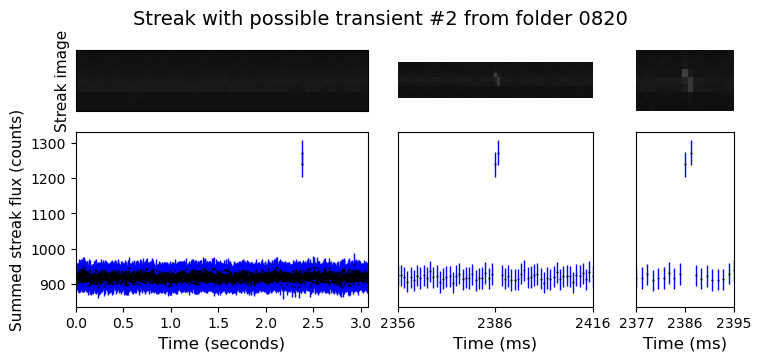

In [11]:
ff.plot_time_series_from_df_tot_no_norm_poisson_error(df_0820, 2, "0820")

In [12]:
fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/0820_minus_extras/"
fname = "ztf_20220820237546_000798_zr_c05_x_0000.fits.fz"

/lustre/lrspec/ZTF_data/science_extractions/to_extract/0820_minus_extras/ztf_20220820237546_000798_zr_c05_x_0000.fits.fz


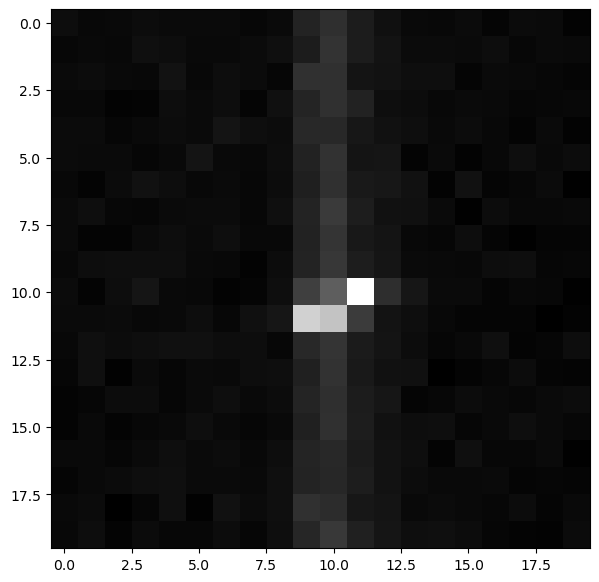

In [13]:
path = fpath + fname
hdul = fits.open(path)
print(path)
file1_array = hdul[1].data
norm = (file1_array - np.min(file1_array)) / (
    np.max(file1_array) - np.min(file1_array)
)  # norm
stamp = file1_array[2376 + 10 - 10 : 2376 + 10 + 10, 1487 + 10 - 10 : 1487 + 10 + 10]
plt.imshow(stamp)

In [17]:
np.argwhere(stamp > 400)

array([[10, 11]])

In [18]:
LL[10, 11]

NameError: name 'LL' is not defined

In [ ]:
stamp[10, 11]

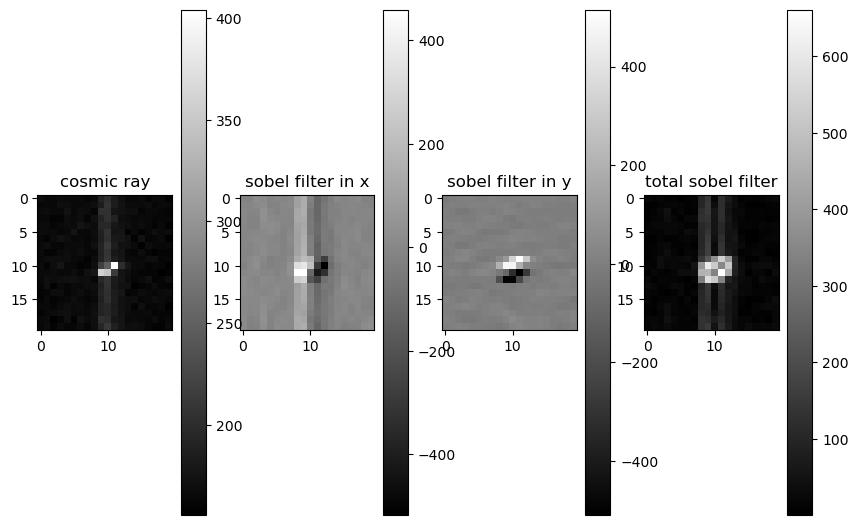

In [28]:
# -- note that there is a sobel filter in scipy.ndimage.filters as well
from scipy.ndimage import sobel

Lx = sobel(stamp, axis=1)  # column axis
Ly = sobel(stamp, axis=0)  # rows axis
LL = np.sqrt(Lx**2 + Ly**2)

fig, ax = plt.subplots(1, 4)
st = ax[0].imshow(stamp)
# # ll = ax[1].imshow(LL>400)
# ll = ax[1].imshow(Ly)
# ax[1].set_title("sobel filter")
# ax[0].set_title("original image (probable cosmic ray)")
# fig.colorbar(ll)
# fig.colorbar(st)

lx = ax[1].imshow(Lx)
ly = ax[2].imshow(Ly)
ll = ax[3].imshow(LL)
ax[2].set_title("sobel filter in y")
ax[1].set_title("sobel filter in x")
ax[3].set_title("total sobel filter")
ax[0].set_title("cosmic ray")
fig.colorbar(ly)
fig.colorbar(lx)
fig.colorbar(ll)
fig.colorbar(st)

fig.show()

In [15]:
img = np.load(
    "full_image_implants/images/ztf_20220820237546_000798_zr_c10_x_0000__implanted10plus.npy"
)
stamp_imp = img[3027 - 10 : 3027 + 10, 95 - 10 : 95 + 10]
# plt.imshow(stamp)

In [16]:
np.load(
    "full_image_implants/info/ztf_20220820237546_000798_zr_c10_x_0000__implanted10plus_info.npy"
)

array([[9.500e+01, 3.027e+03, 9.000e+00, 3.000e+00],
       [5.070e+02, 1.241e+03, 1.010e+00, 3.000e+00],
       [8.390e+02, 1.858e+03, 1.300e+00, 3.000e+00],
       [9.460e+02, 7.820e+02, 1.500e+00, 3.000e+00],
       [9.820e+02, 5.800e+01, 1.050e+00, 3.000e+00],
       [1.021e+03, 2.426e+03, 7.000e+00, 3.000e+00],
       [1.053e+03, 1.154e+03, 1.010e+00, 3.000e+00],
       [1.383e+03, 2.758e+03, 1.050e+00, 3.000e+00],
       [1.715e+03, 6.200e+02, 1.010e+00, 3.000e+00],
       [2.662e+03, 2.569e+03, 1.050e+00, 3.000e+00]])

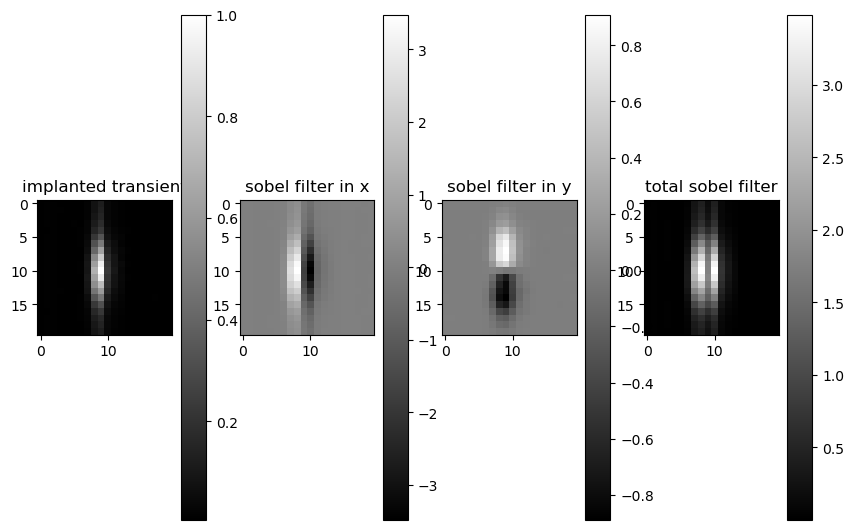

In [17]:
Lx = sobel(stamp_imp, axis=1)  # column axis
Ly = sobel(stamp_imp, axis=0)  # rows axis
LL = np.sqrt(Lx**2 + Ly**2)

fig, ax = plt.subplots(1, 4)
st = ax[0].imshow(stamp_imp)
lx = ax[1].imshow(Lx)
ly = ax[2].imshow(Ly)
ll = ax[3].imshow(LL)
ax[2].set_title("sobel filter in y")
ax[1].set_title("sobel filter in x")
ax[3].set_title("total sobel filter")
ax[0].set_title("implanted transient")
fig.colorbar(ly)
fig.colorbar(lx)
fig.colorbar(ll)
fig.colorbar(st)
fig.show()

In [18]:
np.max(LL)

3.4822311

In [ ]:
# making a gaussian of size 1 to check

In [19]:
def gaussian_event(ys, M, sig, A, original_values):
    """ys should be the array of y values
    #m is the center y value
    #sig is the standard deviation
    #original_values is the original brightness (for each y value)
    #A is the maximum brightening. A-1 is in the code bc of that additional 1 later
    #return original_values * ((A-1) * (np.exp(-np.power(ys - M, 2.) / (2 * np.power(sig, 2.)))) + 1)
    """
    return original_values * (
        (A - 1) * (np.exp(-np.power(ys - M, 2.0) / (2 * np.power(sig, 2.0)))) + 1
    )

In [20]:
def get_image_background(image):
    """
    this function gets the background value of an array of various brightnesses
    and iteratively clips the maximum at a 3 standard deviation level to get the background value
    input: array of any dimensions
    return: background value (float)
    """

    change = 100
    newnorm = image
    while np.abs(change) > 0.0001:
        stdv = np.std(newnorm)
        norm_mean = np.mean(newnorm)
        newnorm = np.clip(
            newnorm, 0, norm_mean + 3 * stdv
        )  # check - is this the right cutoff
        newnorm_mean = np.mean(newnorm)
        change = newnorm_mean - norm_mean
        background = newnorm_mean
    return background

In [21]:
def make_one_stamp_gaussian(stamp, intensity, sigma):
    """
    this function takes an image and implants a gaussian brightening event in the given columns (in a streak).
    inputs -
    image: an array of brightness values
    streak_x_val: location of the streak - x coordinate
    center_value_y: the y value to center the gaussian at
    sigma: the sigma of the gaussian
    intensity: the maximum brightening of the gaussian
    returns:  gaussianed_image, normalized array with brightening in the streak
    """
    streak_x_val = 10
    center_value_y = 10

    # getting background
    background = get_image_background(stamp)

    # subtracting background
    imagenobackground = stamp - np.full(np.shape(stamp), background)

    # choosing which columns are part of the streak (to implant transient in)
    # careful: there could be two streaks in the image, i want the one that is the most centered
    # for now we're just taking the columns around the streak
    mid = streak_x_val  # the middle column - truncated. so the lower one if even number of columns

    averages = np.average(imagenobackground, axis=0)
    # there should be some criteria for the gradient perhaps
    # failing that, just that it's bigger than .05
    column_indices = []
    indices_to_check = []
    if mid < 3072 - 4:
        indices_to_check = [
            mid - 4,
            mid - 3,
            mid - 2,
            mid - 1,
            mid,
            mid + 1,
            mid + 2,
            mid + 3,
        ]
    for index in indices_to_check:
        if averages[index] > 0.01:
            column_indices.append(index)

    # print(column_indices)

    # now gaussianning all relevant columns

    gaussianed_image = (
        imagenobackground.copy()
    )  # stamp array to modify with the gaussian brightening

    for i in column_indices:
        gaussianed = gaussian_event(
            ys=np.linspace(0, stamp.shape[0] - 1, stamp.shape[0]),
            M=center_value_y,
            sig=sigma,
            A=intensity,
            original_values=imagenobackground[:, i],
        )
        gaussianed_image[:, i] = gaussianed

    # adding back background
    gaussianed_image = gaussianed_image + np.full(np.shape(stamp), background)

    # should renormalize it
    norm_gi = (gaussianed_image - np.min(gaussianed_image)) / (
        np.max(gaussianed_image) - np.min(gaussianed_image)
    )
    return norm_gi

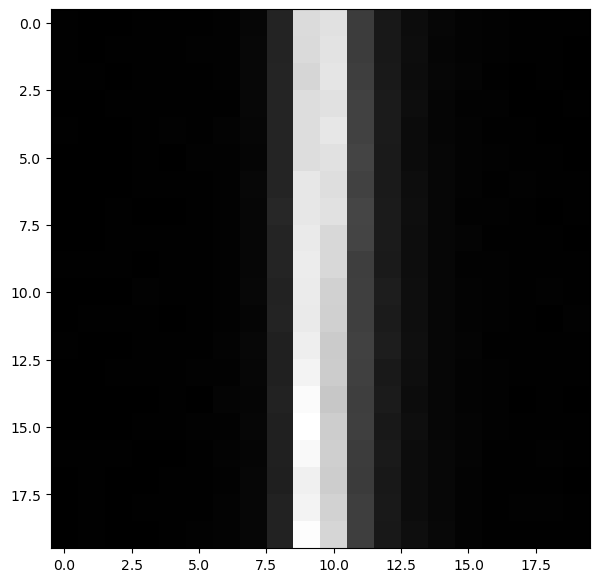

In [22]:
# getting a stamp
stamp_g1 = norm[1500:1520, 734:754]
plt.imshow(stamp_g1)

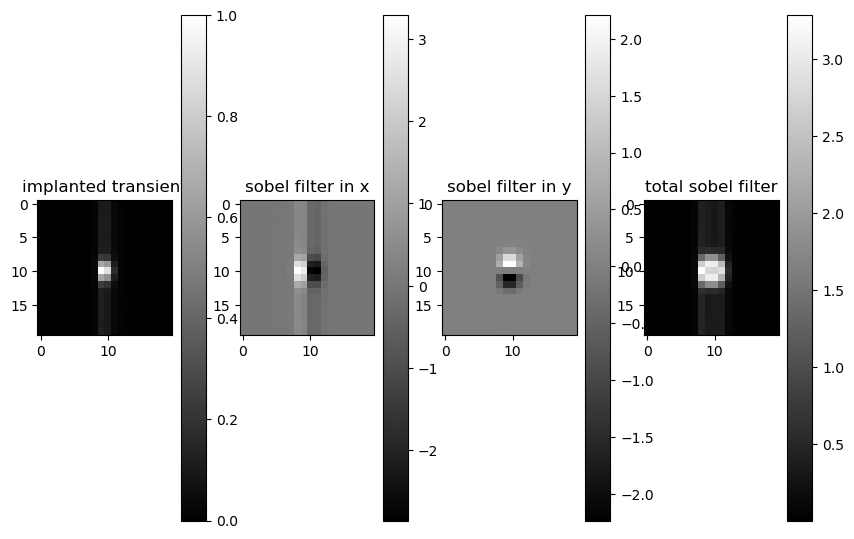

In [26]:
gaus = make_one_stamp_gaussian(stamp_g1, 10, 1)
Lx = sobel(gaus, axis=1)  # column axis
Ly = sobel(gaus, axis=0)  # rows axis
LL = np.sqrt(Lx**2 + Ly**2)

fig, ax = plt.subplots(1, 4)
st = ax[0].imshow(gaus)
# ll = ax[1].imshow(Ly)
# ax[1].set_title("sobel filter")
# ax[0].set_title("original image (implanted transient)")
# fig.colorbar(ll)
# fig.colorbar(st)

lx = ax[1].imshow(Lx)
ly = ax[2].imshow(Ly)
ll = ax[3].imshow(LL)
ax[2].set_title("sobel filter in y")
ax[1].set_title("sobel filter in x")
ax[3].set_title("total sobel filter")
ax[0].set_title("implanted transient")
fig.colorbar(ly)
fig.colorbar(lx)
fig.colorbar(ll)
fig.colorbar(st)

fig.show()

In [29]:
# okay so let's make it a number
sobel_ratio = np.max(Lx) / np.max(Ly)  # we want this to be as large as possible
sobel_ratio

0.8912473

In [30]:
def get_sobel_ratio(stamp):
    """
    input: stamp: 2d brightnesses array with candidate transient
    larger = less likely to be a cosmic ray
    returns sobel_ratio = np.max(Lx)/np.max(Ly) where x is columns axis and y is rows axis
    """
    Lx = sobel(stamp, axis=1)  # column axis
    Ly = sobel(stamp, axis=0)  # rows axis
    sobel_ratio = np.max(Lx) / np.max(Ly)  # we want this to be as large as possible
    return sobel_ratio

In [33]:
ff.get_sobel_ratio(gaus)

1.4878162

In [32]:
importlib.reload(ff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>